# C4 · COMPAS: error disparities, targets and fairness tradeoffs

**Case data:** original ProPublica COMPAS public research release: https://github.com/propublica/compas-analysis  
**Core papers:** Zafar et al. (2017), https://arxiv.org/abs/1610.08452, and Chouldechova (2017), https://arxiv.org/abs/1703.00056.  
**Supporting theory:** Hardt, Price & Srebro (2016), https://arxiv.org/abs/1610.02413.  
**Evidence:** original public benchmark; a direct audit of historical COMPAS ordinal scores; a separate scikit-learn teaching classifier and threshold experiment. The teaching classifier is not COMPAS and does not reproduce Zafar's original constrained optimizer.  
**Full guided lesson:** about 90–120 minutes. The class core is the historical-score audit; model fitting and calibration are optional worked self-study sections.  
**Learning goal:** recognize unequal error burdens, question the outcome label and evaluate a solution without selecting it on the final test set.

### How students use this notebook

Run cells in order. Pause at every **Student task** and record your expectation before showing the worked answer. Name the numerator, denominator, unit and decision rule beside each reported number. The raw folder preserves inputs; the processed folder holds documented teaching tables. Rebuild processed data with `python scripts/process_data.py` from the package root. The source manifest records download versions and distinguishes generated inputs.

For the 150-minute lesson, your team completes the core sections assigned in `INSTRUCTOR_GUIDE.md`. The full notebook takes longer and can support self-study. Part 2 is deliberately unfinished. Running Part 1 supplies a baseline; it does not constitute a final project. Use only data whose provenance and permitted use you can explain.

**Instructor / course:** ____________________  
**Student / team / date:** ____________________

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
            if (p / "data/DATA_MANIFEST.json").exists())
sys.path.insert(0, str(ROOT / "src"))
from fairness_lab import (load_table, audit_table, confusion_counts, rates, rate_gaps,
    wilson_interval, bootstrap_mean_interval, paired_summary, matching_scores, alleged_age_veto)
SEED=42
pd.set_option("display.max_columns",25)
pd.set_option("display.max_rows",25)
pd.set_option("display.float_format",lambda x:f"{x:.4f}")
plt.rcParams.update({"figure.figsize":(9,4.5),"axes.spines.top":False,
    "axes.spines.right":False,"font.size":11})
%matplotlib inline
print("Local data only. No API key, paid model, or live LLM is needed.")

Local data only. No API key, paid model, or live LLM is needed.


## Part 1 — Guided theory and practice

### 1.1 Paper in focus

The paper develops disparate mistreatment as a difference in classification errors across groups and proposes constraints for decision-boundary classifiers. Its experiments include synthetic data and the public COMPAS recidivism benchmark. This notebook focuses on that real benchmark and error-rate auditing. It uses an ordinary scikit-learn logistic model and a separate threshold demonstration; these are teaching implementations, not the authors’ optimization algorithm.

Treatment concerns how attributes enter a decision; impact concerns distributions of decisions; mistreatment concerns errors conditional on an observed reference label. These lenses can give different answers. None is by itself a legal finding, and the label’s validity matters to every conditional error measure.

### 1.2 Recognize the decision direction and data history

Here `y=1` means an observed two-year recidivism label, and a positive prediction is a **high-risk flag**. It is adverse rather than a benefit such as an interview. A false positive flags someone with no observed positive outcome; it is not “giving an unqualified person an opportunity”. The data are an old, local US criminal-justice cohort, useful for studying the paper’s method but not representative of present-day hiring or every justice system.

In [2]:
all_groups=load_table("04_compas","all_groups.csv.gz")
data=load_table("04_compas","black_white.csv.gz")
flow=load_table("04_compas","filter_flow.csv")
display(flow)
display(all_groups.groupby("race").y.agg(n="size",observed_prevalence="mean"))
print("Two-group teaching cohort:",len(data),"records")
assert data.record_id.is_unique and data.y.isin([0,1]).all()
assert not {"name","dob","r_offense_date","two_year_recid"}.intersection(data.columns)

,step,n
0,raw,7214
1,known screening-arrest interval,6907
2,screening within plus/minus 30 days,6172
3,known is_recid flag,6172
4,exclude ordinary traffic charges,6172
5,known COMPAS score text,6172
6,Black/White comparative cohort,5278


,n,observed_prevalence
race,,
African-American,3175,0.5231
Asian,31,0.2581
Caucasian,2103,0.3909
Hispanic,509,0.3713
Native American,11,0.4545
Other,343,0.3615


Two-group teaching cohort: 5278 records


### Dataset, features, outputs and target

The supplied original CSV has 7,214 records from the public research release. Conventional screening and known-case filters produce 6,172 records across all source race groups, then 5,278 records for the specific African-American/Caucasian comparison. These restricted cohorts do not represent every person subject to criminal-justice decisions.

| Field | Role | Ethical or engineering issue |
|---|---|---|
| `record_id` | Source ID for splits and paired policy comparisons | Check uniqueness; remove direct identifiers from classroom tables. |
| `race`, `sex` | Recorded audit groups | Retain source categories and group support. They are not inferred from names. |
| `age`, `age_cat` | Available context/predictor | Age can reflect population/justice-process differences; do not assume causal effects. |
| `priors_count`, `c_charge_degree` | Recorded criminal-history/charge features | Institutional exposure, policing and measurement can influence these fields. |
| `decile_score` | Existing COMPAS ordinal score 1–10 | Positive flag below is score ≥5. This score is not a known probability and is excluded from the new classifier's inputs. |
| `y` (raw `two_year_recid`) | Recorded two-year reference outcome | It is a criminal-justice measurement, not observation of all harmful behaviour. |
| New `score`, `decision` | Output from the separate teaching logistic model | Do not describe them as COMPAS predictions or deploy the classroom model. |

`decision=1` is an adverse high-risk flag. FPR therefore concerns people with recorded `y=0` who receive that flag. Compare this with C1/C3, where a positive decision advances an applicant. The direction of harm must follow the application.

### Core raw-to-processed checkpoint

The processing script counts each exclusion sequentially: missing screening/arrest interval, interval outside ±30 days, unknown recidivism flag, ordinary traffic charge, unavailable score text, and finally the optional two-race restriction. Names, birth dates, case identifiers, detailed charge descriptions and outcome-derived features are absent from the classroom table. The original raw file stays unchanged for provenance.

**Student task:** Trace the difference between 7,214 and 5,278. Which records disappeared because of a measurement rule versus a chosen group comparison? How could these filters change what a fairness statement means?

In [3]:
raw=pd.read_csv(ROOT/"data/raw/04_compas/compas-scores-two-years.csv")
print("Original research-release rows:",len(raw))
assert len(raw)==7214
display(load_table("04_compas","filter_flow.csv"))
historical=load_table("04_compas","black_white.csv.gz")
historical["decision"]=historical.decile_score.ge(5).astype(int)
vendor_audit=audit_table(historical,group="race")
display(Markdown("**Historical-score audit at decile score ≥5, not the new classifier**"))
display(vendor_audit[["n","positives","negatives","TP","FP","FN","TN","FPR","FNR","TPR","PPV","accuracy"]])
assert vendor_audit.loc["African-American","FP"]==641
assert vendor_audit.loc["African-American","TN"]==873
assert vendor_audit.loc["Caucasian","FP"]==282
assert vendor_audit.loc["Caucasian","TN"]==999
print("African-American FPR:",641,"/",641+873,"=",641/(641+873))
print("Caucasian FPR:",282,"/",282+999,"=",282/(282+999))
print("Signed FPR gap (pp):",100*(641/1514-282/1281))

Original research-release rows: 7214


,step,n
0,raw,7214
1,known screening-arrest interval,6907
2,screening within plus/minus 30 days,6172
3,known is_recid flag,6172
4,exclude ordinary traffic charges,6172
5,known COMPAS score text,6172
6,Black/White comparative cohort,5278


**Historical-score audit at decile score ≥5, not the new classifier**

,n,positives,negatives,TP,FP,FN,TN,FPR,FNR,TPR,PPV,accuracy
group,,,,,,,,,,,,
African-American,3175.0000,1661.0000,1514.0000,1188.0000,641.0000,473.0000,873.0000,0.4234,0.2848,0.7152,0.6495,0.6491
Caucasian,2103.0000,822.0000,1281.0000,414.0000,282.0000,408.0000,999.0000,0.2201,0.4964,0.5036,0.5948,0.6719


African-American FPR: 641 / 1514 = 0.4233817701453104
Caucasian FPR: 282 / 1281 = 0.22014051522248243
Signed FPR gap (pp): 20.3241254922828


### Worked denominators and error burdens

For African-American records, FPR = 641/(641+873) = 42.338%. For Caucasian records, FPR = 282/(282+999) = 22.014%. The signed difference is 20.324 percentage points. Each denominator includes only records with the reference label `y=0`, not all group records or all high-risk flags.

FNR uses `y=1` records: 473/(1,188+473) = 28.477% versus 408/(414+408) = 49.635%. Different errors disadvantage different people. Neither equal aggregate accuracy nor one chosen parity criterion resolves the outcome label's validity or the justice system's institutional harms.

**Student task:** Recompute one FPR, one FNR and one PPV by hand. Then propose a change and identify which other error must be checked before recommending it. These are our reproducible descriptive calculations on a stated filtered cohort, not an exact reproduction of every published result.

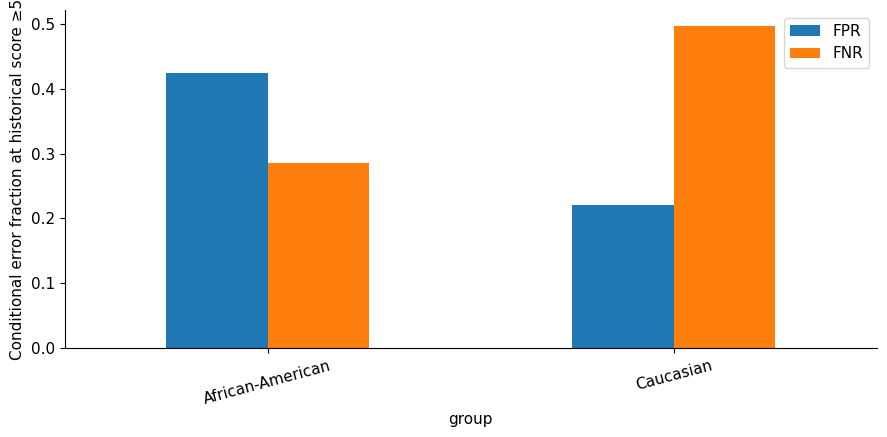

,prevalence,TPR,FPR,PPV,PPV_reconstructed
group,,,,,
African-American,0.5231,0.7152,0.4234,0.6495,0.6495
Caucasian,0.3909,0.5036,0.2201,0.5948,0.5948


In [4]:
plot=vendor_audit[["FPR","FNR"]].copy()
plot.plot.bar();plt.ylabel("Conditional error fraction at historical score ≥5")
plt.xticks(rotation=15);plt.tight_layout();plt.show()
table=vendor_audit.copy()
table["PPV_reconstructed"]=(table.TPR*table.prevalence)/(
    table.TPR*table.prevalence+table.FPR*(1-table.prevalence))
display(table[["prevalence","TPR","FPR","PPV","PPV_reconstructed"]])
assert np.allclose(table.PPV,table.PPV_reconstructed)

### Calibration and parity are different questions

Chouldechova explains why unequal base rates can create tradeoffs between predictive-value and error-rate criteria under relevant imperfect-prediction conditions. Hardt et al. formulate equality of opportunity (equal TPR) and equalized odds (equal TPR and FPR). Perfect and degenerate cases need separate handling; this is not a theorem that every pair of fairness notions is always incompatible.

The identity `PPV = TPR×prevalence / [TPR×prevalence + FPR×(1−prevalence)]` shows exactly how the quantities connect. The previous cell verifies it against observed confusion counts. It is an algebraic identity, not a causal explanation of why base rates differ.

For a calibrated probability, predicted probability should match outcome frequency in comparable bins. An ordinal decile 7 is not automatically a 70% probability. The chart below shows observed outcome fractions by ordinal score, without drawing a misleading “perfect calibration” diagonal.

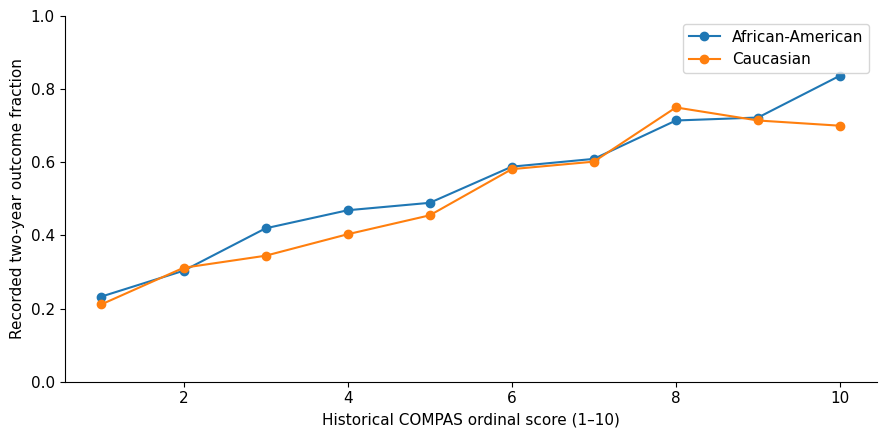

,race,decile_score,n,observed_rate
0,African-American,1,365,0.2329
1,African-American,2,346,0.3035
2,African-American,3,298,0.4195
3,African-American,4,337,0.4688
4,African-American,5,323,0.4892
5,African-American,6,318,0.5881
6,African-American,7,343,0.6093
7,African-American,8,301,0.7143
8,African-American,9,317,0.7224
9,African-American,10,227,0.8370


In [5]:
ordinal=data_for_bins=historical.groupby(["race","decile_score"]).y.agg(n="size",observed_rate="mean").reset_index()
for group,part in ordinal.groupby("race"):
    plt.plot(part.decile_score,part.observed_rate,marker="o",label=group)
plt.xlabel("Historical COMPAS ordinal score (1–10)")
plt.ylabel("Recorded two-year outcome fraction");plt.ylim(0,1);plt.legend()
plt.tight_layout();plt.show()
display(ordinal.head(10))

### Optional worked self-study: a separately trained classroom model

The remaining guided code uses scikit-learn logistic regression and a train/validation/test split. It demonstrates protected-column omission, threshold selection and independent evaluation. Its features, parameters and probability scores differ from the historical vendor system above. Group-specific thresholds are a methodological experiment with ethical and legal implications; they are not a deployment recommendation.

**Core-class stopping point:** after the direct historical-score audit and ethical diagnosis below, teams can move to the recommendation template. Study the new-model experiment after class or as a baseline for Part 2.

### 1.3 Cohort selection and the label are part of the audit

The processing flow follows the conventional screening-date window and unknown-case/charge/score filters, then explicitly restricts the paper-focused comparison to African-American and Caucasian source categories. The all-group table remains available for a broader project. Excluded groups do not stop mattering because an analysis is easier with two categories.

The outcome reflects what was recorded in a criminal-justice process. Arrest, detection, exposure to policing, detention and available follow-up can differ across groups. “No recorded recidivism” is not proof of no offending; recorded recidivism is not an unbiased measure of a person’s intrinsic criminality. A more equal error rate against a distorted label can still preserve harm.

**Student task:** Explain one selection filter, one excluded group and one label limitation. Name a field that would leak future information if used as an input feature.

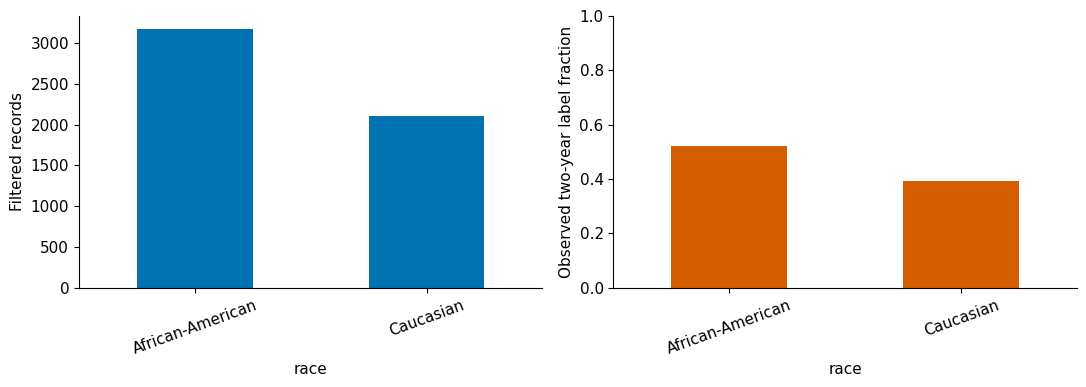

In [6]:
fig,axes=plt.subplots(1,2,figsize=(11,4))
data.groupby("race").size().plot.bar(ax=axes[0],color="#0072B2")
axes[0].set_ylabel("Filtered records")
data.groupby("race").y.mean().plot.bar(ax=axes[1],color="#D55E00")
axes[1].set_ylabel("Observed two-year label fraction");axes[1].set_ylim(0,1)
for ax in axes:ax.tick_params(axis="x",rotation=20)
plt.tight_layout();plt.show()

### 1.4 Split before fitting preprocessing or a model

We create training, validation and test subsets of 70%, 15% and 15%, stratified by race×label. The stratification helps preserve support for conditional error calculations; it does not remove bias. Preprocessing is fitted inside a pipeline using training rows only. Future-outcome fields, COMPAS output scores and identifiers are excluded from our model features.

One model uses age category, prior-count and charge-degree features. A comparison model also uses the protected race and sex source fields. This comparison makes feature treatment visible; it is not a recommendation to deploy either. Removing an explicit group column does not remove correlated proxies or historical disparities.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

stratum=data.race.astype(str)+"|"+data.y.astype(str)
train,remaining=train_test_split(data,test_size=.30,random_state=SEED,stratify=stratum)
validation,test=train_test_split(remaining,test_size=.50,random_state=SEED,
                                stratify=remaining.race.astype(str)+"|"+remaining.y.astype(str))
assert not set(train.record_id)&set(test.record_id)
assert not set(validation.record_id)&set(test.record_id)
print("Train / validation / test:",len(train),len(validation),len(test))

def build_model(include_protected=False):
    categorical=["age_cat","c_charge_degree"]+(["race","sex"] if include_protected else [])
    preprocessing=ColumnTransformer([
        ("categorical",OneHotEncoder(handle_unknown="ignore"),categorical),
        ("numeric",StandardScaler(),["priors_count"])])
    return make_pipeline(preprocessing,LogisticRegression(max_iter=1000,random_state=SEED))

omit_model=build_model(False).fit(train,train.y)
include_model=build_model(True).fit(train,train.y)
val=validation.copy()
val["score"]=omit_model.predict_proba(val)[:,1]
val["decision"]=val.score.ge(.5).astype(int)
display(audit_table(val,group="race")[["n","TP","FP","FN","TN","accuracy","selection_rate","TPR","FPR","FNR"]])

Train / validation / test: 3694 792 792


,n,TP,FP,FN,TN,accuracy,selection_rate,TPR,FPR,FNR
group,,,,,,,,,,
African-American,476.0000,176.0000,89.0000,73.0000,138.0000,0.6597,0.5567,0.7068,0.3921,0.2932
Caucasian,316.0000,47.0000,27.0000,77.0000,165.0000,0.6709,0.2342,0.3790,0.1406,0.6210


### 1.5 Compare treatment choices using validation data

**Student task:** Does the model omitting protected columns necessarily have a smaller error disparity? Before running this comparison, describe two reasons the answer might be no. Compare accuracy and signed group error differences as well as the largest-minus-smallest gap.

This is a controlled comparison of two feature sets under our training procedure. It does not identify which historical mechanism caused a disparity. Race/sex information is retained for auditing in both cases even when omitted from model inputs.

In [8]:
feature_comparison=[]
for name,model in [("Protected columns omitted",omit_model),("Protected columns included",include_model)]:
    frame=validation.assign(decision=(model.predict_proba(validation)[:,1]>=.5).astype(int))
    table=audit_table(frame,group="race")
    feature_comparison.append({"feature_choice":name,"accuracy":frame.decision.eq(frame.y).mean(),**rate_gaps(table).to_dict()})
display(pd.DataFrame(feature_comparison).set_index("feature_choice").rename(columns={"selection_rate":"selection_gap_pp", "TPR":"TPR_gap_pp", "FPR":"FPR_gap_pp", "FNR":"FNR_gap_pp", "PPV":"PPV_gap_pp"}))

,accuracy,selection_gap_pp,TPR_gap_pp,FPR_gap_pp,PPV_gap_pp
feature_choice,,,,,
Protected columns omitted,0.6641,32.2545,32.7795,25.1445,2.9016
Protected columns included,0.6692,37.2008,38.4117,29.4305,0.5154


### 1.6 Fit a disclosed threshold rule on validation data

For a simple disparate-mistreatment experiment, choose a target validation FPR of 20% and, for each group, the available threshold closest to it. This target is a **teaching choice**, not a recommended policy. FPR conditions on `y=0`, so it can be counted only where observed negatives exist. This procedure uses group membership at decision time and does not enforce FNR or selection parity.

The thresholds are selected from validation data and then frozen. The final test result must not be used to adjust them. A policy using different group thresholds raises normative and legal questions that require deployment-specific review; numerical parity does not resolve those questions.

For an idealized error constraint, one might require the absolute FPR difference to be no more than a tolerance ε while minimizing prediction loss. Exact classification indicators make such constraints difficult to optimize directly. The paper studies a specific optimization approach; our threshold experiment supplies an accessible comparison rather than its optimizer.

In [9]:
TARGET_FPR=.20
grid=np.linspace(0,1,101)
thresholds={}
diagnostics=[]
for group,part in val.groupby("race"):
    assert part.y.eq(0).any()
    options=[]
    for threshold in grid:
        result=rates(confusion_counts(part.y,part.score.ge(threshold).astype(int)))
        options.append({"threshold":threshold,**result})
    options=pd.DataFrame(options)
    options["distance"]=(options.FPR-TARGET_FPR).abs()
    choice=options.sort_values(["distance","accuracy","threshold"],ascending=[True,False,False]).iloc[0]
    thresholds[group]=float(choice.threshold)
    diagnostics.append({"group":group,"threshold":choice.threshold,"validation_FPR":choice.FPR,
                        "validation_FNR":choice.FNR,"target_FPR":TARGET_FPR})
display(pd.DataFrame(diagnostics).set_index("group"))
print("Frozen thresholds:",thresholds)

,threshold,validation_FPR,validation_FNR,target_FPR
group,,,,
African-American,0.5900,0.1938,0.5462,0.2000
Caucasian,0.4700,0.2083,0.5403,0.2000


Frozen thresholds: {'African-American': 0.59, 'Caucasian': 0.47000000000000003}


### 1.7 Evaluate the frozen comparison on the held-out test subset

**Student task:** Predict which quantities the threshold rule is designed to change and which it is not designed to control. Run the cell once after freezing the policy. If the test FPR gap remains, explain why matching validation rates does not guarantee matching population rates.

The table includes all four confusion counts and their denominators. A useful recommendation considers total adverse flags, FPR, FNR, subgroup support, uncertainty and label limitations together. Changing a threshold does not repair the underlying reference labels.

**Common threshold 0.5**

,n,positives,negatives,TP,FP,FN,TN,accuracy,TPR,FPR,FNR,selection_rate
group,,,,,,,,,,,,
African-American,477.0000,250.0000,227.0000,161.0000,78.0000,89.0000,149.0000,0.6499,0.6440,0.3436,0.3560,0.5010
Caucasian,315.0000,123.0000,192.0000,58.0000,47.0000,65.0000,145.0000,0.6444,0.4715,0.2448,0.5285,0.3333


**Validation-fitted group FPR thresholds**

,n,positives,negatives,TP,FP,FN,TN,accuracy,TPR,FPR,FNR,selection_rate
group,,,,,,,,,,,,
African-American,477.0000,250.0000,227.0000,109.0000,31.0000,141.0000,196.0000,0.6394,0.4360,0.1366,0.5640,0.2935
Caucasian,315.0000,123.0000,192.0000,67.0000,56.0000,56.0000,136.0000,0.6444,0.5447,0.2917,0.4553,0.3905


,accuracy,high_risk_flags,selection_gap_pp,TPR_gap_pp,FPR_gap_pp,PPV_gap_pp
rule,,,,,,
Common threshold 0.5,0.6477,344,16.7715,17.2455,9.8821,12.1259
Validation-fitted group FPR thresholds,0.6414,263,9.6975,10.8715,15.5103,23.3856


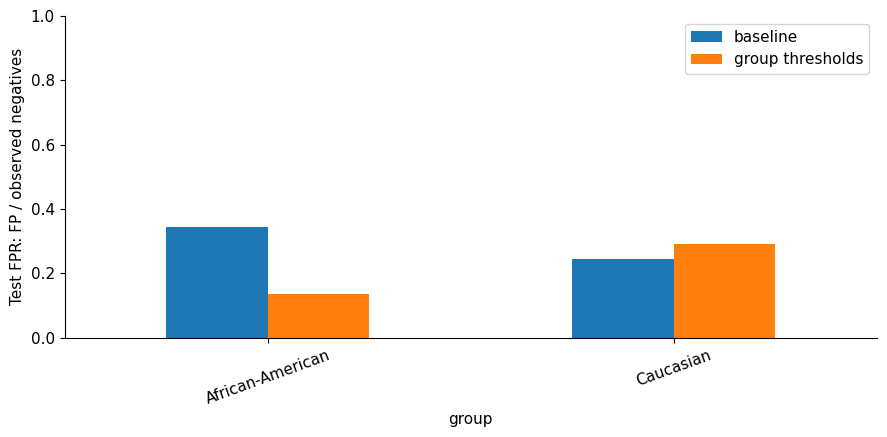

In [10]:
from IPython.display import Markdown
test_scored=test.assign(score=omit_model.predict_proba(test)[:,1])
baseline=test_scored.assign(decision=test_scored.score.ge(.5).astype(int))
mitigated=test_scored.assign(decision=test_scored.score.ge(test_scored.race.map(thresholds)).astype(int))
comparison=[]
for name,frame in [("Common threshold 0.5",baseline),("Validation-fitted group FPR thresholds",mitigated)]:
    table=audit_table(frame,group="race")
    display(Markdown("**"+name+"**"));display(table[["n","positives","negatives","TP","FP","FN","TN","accuracy","TPR","FPR","FNR","selection_rate"]])
    comparison.append({"rule":name,"accuracy":frame.y.eq(frame.decision).mean(),
        "high_risk_flags":int(frame.decision.sum()),**rate_gaps(table).to_dict()})
display(pd.DataFrame(comparison).set_index("rule").rename(columns={"selection_rate":"selection_gap_pp", "TPR":"TPR_gap_pp", "FPR":"FPR_gap_pp", "FNR":"FNR_gap_pp", "PPV":"PPV_gap_pp"}))
ax=pd.concat({"baseline":audit_table(baseline,group="race").FPR,
              "group thresholds":audit_table(mitigated,group="race").FPR},axis=1).plot.bar()
ax.set_ylabel("Test FPR: FP / observed negatives");ax.set_ylim(0,1)
plt.xticks(rotation=20);plt.tight_layout();plt.show()

### 1.8 Uncertainty and ethical response

We can display Wilson intervals for the two test FPR estimates as a first denominator check. They describe rate uncertainty under a binomial approximation. They are not an interval for the improvement in the **gap**; a project should compare the two rules on the same resampled test people. Original-data selection, policing patterns and label error are outside these intervals.

**Worked-result hint:** In the saved run, the test FPR gap increases from about 9.9 to 15.5 percentage points. The chosen validation-target rule therefore fails to improve this primary disparity on the test subset. Explain this negative result using the displayed counts and possible sampling/discrete-score effects; do not retune using the final test subset.

In [11]:
for group,row in audit_table(mitigated,group="race").iterrows():
    lo,hi=wilson_interval(row.FP,row.negatives)
    print(f"{group}: FPR={row.FP:.0f}/{row.negatives:.0f}={row.FPR:.1%}; interval [{lo:.1%}, {hi:.1%}]")
project_data=data.copy()

African-American: FPR=31/227=13.7%; interval [9.8%, 18.7%]
Caucasian: FPR=56/192=29.2%; interval [23.2%, 36.0%]


| Diagnostic | Ethical question | Practical response |
|---|---|---|
| Omitting race leaves error gaps | Are proxy/history effects still present? | Inspect features and conditional errors; do not equate omission with fairness |
| FPR improves while FNR rises | Who bears the changed mistakes? | State the harm priority and report both errors |
| Test rates diverge from validation | Is the intervention stable? | Quantify uncertainty; collect new validation evidence before further tuning |
| Historical labels are unevenly observed | What does a “correct” prediction mean? | Examine measurement and follow-up; consider whether the task should be automated |
| Two-group analysis excludes others | Who is absent from the conclusion? | Use all-group data where support permits and show small-n limitations |

**Student task:** Recommend one next step for this teaching audit. Cite two test-set calculations and one issue that statistical parity cannot fix. Do not propose operational criminal-justice decisions based on this classroom model.

### Optional calibration experiment with separate training roles

Fit an isotonic mapping on the **validation** probabilities from the teaching classifier and evaluate it on the already reserved test records. The mapping is not a vendor-provided probability model. Ten bins can be sparse; show n and avoid declaring subgroup calibration from visually close points alone. This worked section illustrates a measurement procedure, not a proof that the model is suitable for criminal-justice use.

,race,bin,n,mean_probability,observed_rate
0,African-American,"(0.2, 0.4]",159,0.2833,0.3522
1,African-American,"(0.4, 0.6]",135,0.4994,0.4370
2,African-American,"(0.6, 0.8]",166,0.6885,0.7229
3,African-American,"(0.8, 1.0]",17,0.9314,0.8824
4,Caucasian,"(0.2, 0.4]",161,0.2636,0.2547
5,Caucasian,"(0.4, 0.6]",88,0.4986,0.4318
6,Caucasian,"(0.6, 0.8]",64,0.6761,0.6562
7,Caucasian,"(0.8, 1.0]",2,0.9583,1.0000


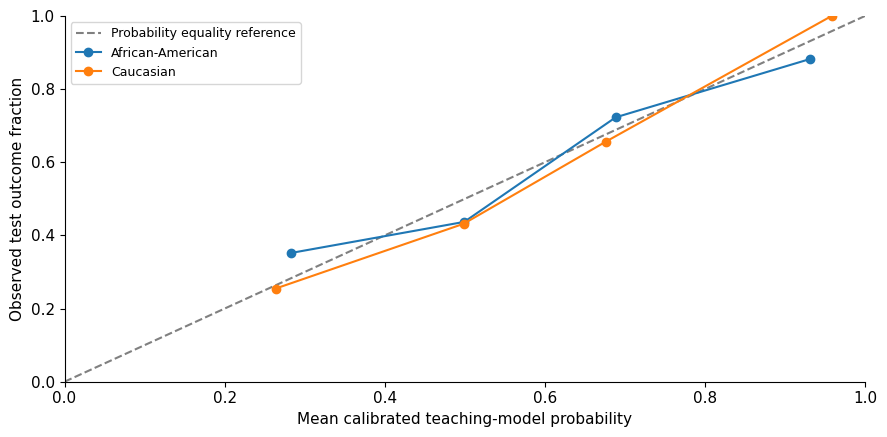

In [12]:
from sklearn.isotonic import IsotonicRegression
calibrator=IsotonicRegression(out_of_bounds="clip").fit(val.score,val.y)
calibration_test=test.copy()
calibration_test["predicted_probability"]=calibrator.predict(omit_model.predict_proba(test)[:,1])
calibration_test["bin"]=pd.cut(calibration_test.predicted_probability,
    bins=np.linspace(0,1,6),include_lowest=True)
reliability=calibration_test.groupby(["race","bin"],observed=True).agg(
    n=("y","size"),mean_probability=("predicted_probability","mean"),observed_rate=("y","mean")).reset_index()
display(reliability)
fig,ax=plt.subplots()
ax.plot([0,1],[0,1],color="grey",linestyle="--",label="Probability equality reference")
for group,part in reliability.groupby("race"):
    ax.plot(part.mean_probability,part.observed_rate,marker="o",label=group)
ax.set_xlabel("Mean calibrated teaching-model probability")
ax.set_ylabel("Observed test outcome fraction");ax.set_xlim(0,1);ax.set_ylim(0,1)
ax.legend(fontsize=9);plt.tight_layout();plt.show()

### Interpreting solutions and remaining problems

The validation-fitted threshold policy can worsen the held-out FPR gap. Keep that negative result and explain it. Do not repeatedly retune thresholds on the test cohort until the graph improves. The original constrained-optimization method, threshold postprocessing and rubric/process reform answer different questions and should not be reported as interchangeable solutions.

| Recognized problem | Evidence | Response to evaluate | What remains unresolved |
|---|---|---|---|
| Unequal adverse false flags | Historical FPR counts and denominators | Prespecified error-focused policy or justified model alternative | Tradeoff with missed positives, utility and legal/process acceptability |
| Label bias | Recorded justice outcome instead of all behaviour | Review label provenance, follow-up and measurement alternatives | Historical data cannot reveal all unobserved conduct |
| Proxy information | Omitting race still leaves correlated history/context | Inspect feature rationale and institutional pathways | Statistical association does not identify a causal pathway |
| Small or excluded groups | Full-group support table and filter flow | Report excluded categories and conditional coverage | Larger cohorts still need appropriate sampling and permissions |
| Conflicting criteria | PPV identity and different prevalence | Justify the harm priority and report remaining metrics | No single metric supplies a complete ethical decision |

**Core-class output:** the stated filter flow, FPR 641/1,514 and 282/1,281, a labelled error plot, and a proposed response that acknowledges measurement bias and another error burden.

**Source-to-method map:** Zafar informs the disparate-mistreatment lens. Hardt informs equal-opportunity/equalized-odds objectives. Chouldechova informs base-rate/calibration tradeoffs. They share this C4 practical notebook, rather than appearing as extra unmatched case notebooks.

## Part 2 — Extend this into a final project

### 2.1 Choose a question and make it falsifiable

**Starting question:** Which error disparity can be reduced under a stated harm priority, and what are the costs on held-out data?

Your unit of analysis is **one person in the filtered COMPAS research cohort**. The suggested primary quantity is **FPR/FNR disparity with a prespecified harm priority**. This is a starting choice to defend, not a universal definition of fairness. Select one main question; a large collection of plots is not a research contribution.

Possible directions:

- Omitting protected inputs may leave conditional error disparities.
- A rule optimized for FPR may worsen FNR, calibration or workload.
- A fairness improvement may be smaller than sampling or label-sensitivity uncertainty.

**TODO — Before calculating new results**, write a short protocol containing: the population and decision; whose interests you prioritize; the primary metric and reference group; the sign of the comparison; one practical effect-size threshold; the split or resampling unit; the intervention; and what evidence would change your recommendation. State which assumptions can be checked with these data and which cannot.

In [13]:
PROJECT_SPEC = {
    "case_id": "C4",
    "question": "TODO: one testable question",
    "unit": 'one person in the filtered COMPAS research cohort',
    "primary_metric": 'FPR/FNR disparity with a prespecified harm priority',
    "reference_group": "TODO",
    "practical_effect_threshold": None,  # TODO: value AND unit
    "validation_plan": "TODO: prevent repeated-unit or test-set leakage",
    "intervention": "TODO",
    "ethics_and_label_assumptions": "TODO",
    "seed": SEED,
}
PROJECT_DIR = ROOT / "reports" / 'C4'
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
display(pd.Series(PROJECT_SPEC, name="Your preregistered choices"))

case_id                                                                        C4
question                                              TODO: one testable question
unit                            one person in the filtered COMPAS research cohort
primary_metric                  FPR/FNR disparity with a prespecified harm pri...
reference_group                                                              TODO
practical_effect_threshold                                                   None
validation_plan                   TODO: prevent repeated-unit or test-set leakage
intervention                                                                 TODO
ethics_and_label_assumptions                                                 TODO
seed                                                                           42
Name: Your preregistered choices, dtype: object

### 2.2 TODO work packages, with implementation hints

1. **TODO: Make the paper-method distinction explicit.** Read the authors’ optimization formulation and list how our baseline differs. Hint: choose either a faithful implementation with documented solver assumptions or a clearly named modern adaptation; do not call a threshold change the original optimizer.
2. **TODO: Implement one substantive mitigation.** Consider reweighting, a constrained learner, or a validation-selected threshold/capacity policy. Hint: compare the same frozen test rows, and specify a utility or workload constraint alongside the fairness objective.
3. **TODO: Estimate an interval for the change in a gap.** Bootstrap test record_id values and evaluate both rules on the same sample. Hint: retain subgroup support and compute the difference of gaps inside each replicate.
4. **TODO: Audit intersections or excluded groups.** Extend to race×sex or all source categories. Hint: display counts and undefined denominators; do not collapse people into “other” merely to get a stable-looking number.
5. **TODO: Probe label sensitivity.** Apply explicitly simulated group-specific label error in a separate sensitivity scenario. Hint: distinguish the simulation from actual corrected labels; report when the recommendation changes.
6. **TODO: Write a decision record.** Include who bears errors, who chose costs and what evidence would justify stopping the automation.

6. **TODO: Compare criteria and probability calibration.** Define one harm-priority objective and report TPR, FPR, PPV and reliability support on the same independent test cohort. Hint: use Chouldechova’s identity to separate mathematical tradeoffs from measurement causes.

### 2.3 Protect the validity of your comparison

Do not tune on the final test set. Avoid post-outcome features and scores as inputs when training this baseline. Explain the adverse direction of positive decisions. Treat the dataset as historical recorded outcomes, not a measure of inherent risk or a deployment recommendation.

Keep raw files unchanged. Put project-specific derived data under `reports/C4/`, record the transformation, and retain a stable identifier for every independent unit. Fit preprocessing and models using training data. Choose thresholds, features and other settings on validation data. Use a test set once for the final comparison; if you revise after seeing it, obtain a new holdout or label the analysis exploratory. For descriptive studies without model training, predefine the comparisons and acknowledge that many subgroup/threshold searches are exploratory.

For uncertainty, resample independent units rather than rows that repeat the same person or profile. Report the number of units, the number of observations, missingness, an effect size and an interval. Document any multiple-testing strategy before interpreting a collection of p-values. A non-significant result is not proof of equivalence. If your purpose is to show effects are small, specify an equivalence margin and use an appropriate procedure.

In [14]:
def student_extension(data, spec):
    """TODO: return a dictionary with results, uncertainty, and a defensible recommendation.

    Suggested keys:
    question, independent_units, preprocessing_log, results_table,
    primary_effect, interval, harms_and_benefits, limitations, recommendation.
    Save figures/tables into PROJECT_DIR; keep evidence separate from interpretation.
    """
    raise NotImplementedError("Implement your research question; Part 1 is the starting point.")

RUN_STUDENT_PROJECT = False  # Set True only after implementing the TODO above.
if RUN_STUDENT_PROJECT:
    project_result = student_extension(project_data.copy(), PROJECT_SPEC)
    assert isinstance(project_result, dict)
    assert {"results_table", "limitations", "recommendation"}.issubset(project_result)
    display(project_result["results_table"])

### 2.4 A useful final submission

Submit the extended notebook with a clean “Restart kernel → Run all” execution, an environment file, a processing log, and a 1,500–2,500 word report. Include one baseline, one substantive extension, one uncertainty or sensitivity analysis, and one clearly stated failure or limitation. The report should answer: **What changed? Who gained or lost? What do the data support? What remains unknown? What should be done next, and by whom?**

Use the supplied project protocol, data-card and audit-report templates. Include an authorship/AI-use statement: identify assistance received, verify generated code and claims yourself, and explain at least one calculation and one design choice without relying on an AI answer. Do not submit a prose conclusion that contradicts your executed results.

| Assessment component | Weight | Evidence expected |
|---|---:|---|
| Research question and justified fairness objective | 15% | Clear decision, stakeholder, unit, and hypothesis |
| Data provenance, quality and ethical analysis | 20% | Traceable source, missingness, label limitations, concrete responses |
| Correct implementation and reproducibility | 25% | Runnable code, denominators, appropriate validation, no leakage |
| Substantive extension and uncertainty | 25% | New analysis/intervention, effect size, sensitivity and limitations |
| Interpretation and communication | 15% | Supported recommendation and honest scope |

### 2.5 Peer review and oral defence

Ask another team to reproduce one figure and one numerical result. They should identify the numerator and denominator, check which records were excluded, and challenge one causal or normative assumption. During a short oral defence, explain why your chosen metric fits the decision, demonstrate an edge case such as an empty subgroup, and name evidence that could reverse your conclusion.

**Submission checklist:** notebook runs; sources cited; no raw data silently changed; all exclusions counted; score scale and decision direction stated; TODOs addressed; results distinguish descriptive evidence from causal or legal claims; privacy and annotator work considered; final recommendation includes a monitoring or reconsideration trigger.

**Exit reflection:** Write three sentences: “Our strongest evidence is …”; “This cannot establish …”; “Our next action is …”.